In [129]:
import os
import chromadb
import pandas as pd

from dotenv import load_dotenv
from pypdf import PdfReader

from openrouter import OpenRouter

### configure environment 

In [130]:
load_dotenv(override=True)

OPENROUTER_API_KEY = os.getenv("OPENROUTER_API_KEY")
OPENROUTER_MODEL = os.getenv("OPENROUTER_MODEL")

if not OPENROUTER_API_KEY:
    raise ValueError("OPENROUTER_API_KEY not found!")

if not OPENROUTER_MODEL:
    raise ValueError("OPENROUTER_MODEL not found!")

llm = OpenRouter(
    api_key=OPENROUTER_API_KEY
)


print(OPENROUTER_MODEL)

print("Environment configured successfully!")


openrouter/free
Environment configured successfully!


### initialize the Chromadb

In [131]:
chroma_client = chromadb.PersistentClient(
    path="./advanced_rag_db"
)

collection = chroma_client.get_or_create_collection(
    name="advanced_rag_documents"
)

print("Collection:", collection.name)
print("Existing documents:", collection.count())

Collection: advanced_rag_documents
Existing documents: 0


### Make document chunk

In [132]:
def slpit_into_chunk(content):
    chunks = []

    start = 0
    while start < len(content):
        end = start + chunk_size
        chunks.append(content[start:end])
        start += chunk_size - overlap
    
    return chunks


In [133]:
with open("../documents.txt", "r", encoding="utf-8") as file:
    content = file.read()

content


"Shuddho is a premier, leading competitive programming team renowned for its excellence in algorithmic problem-solving, advanced data structures, mathematical computation, and high-stakes national programming contests. Founded with the core mission of dominating national and international collegiate programming competitions, Team Shuddho operates as a specialized five-member unit. The roster is led by team leader and chief strategist MAR Miju, who works alongside four elite core members: Mosabbir, Montahina, Sakib, and Ridoy. Unlike conventional three-person collegiate teams that form temporarily for a single season, Shuddho functions as a permanent competitive programming syndicate and research collective. They systematically prepare for the International Collegiate Programming Contest (ICPC) regionals, the National Collegiate Programming Contest (NCPC), and prestigious Inter-University Programming Contests (IUPC), consistently placing in the top tier of the national standings.\n\nThe

In [134]:
chunk_size = 500
overlap = 100

print("chunk started.....................")
chunks= []
start=0
while start < len(content):
    print("chunking..........................")

    end = start + chunk_size
    chunks.append(content[start:end])
    start += chunk_size - overlap
    
print('chunk completed!')

chunk started.....................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking..........................
chunking............

In [135]:
import sys
import os

# Add parent folder (Naive-RAG) to Python path so 'utils' can be found
sys.path.append(os.path.abspath(".."))

from utils.config import (
    create_embeddings,
    store_embeded_cunks,
)

print("Embedding and storage functions imported successfully!")

Embedding and storage functions imported successfully!


### Create embedding
---

In [136]:
from chromadb.utils import embedding_functions

sentence_embedder = embedding_functions.DefaultEmbeddingFunction()
print("Embedding started...")

embeded_chunks = sentence_embedder(chunks )

print("Embedding completed!")

Embedding started...
Embedding completed!


### Store Embedding in Vector Database(chromadb)

In [137]:
# Clear any old records so only current chunks are stored
existing_ids = collection.get()["ids"]
if existing_ids:
    collection.delete(ids=existing_ids)

collection.upsert(
    ids=[f"chunk-{i}" for i in range(len(chunks))],
    documents=chunks,
    embeddings=embeded_chunks,
)
print('stored embeded chunk successfuly')

stored embeded chunk successfuly


### verify Chromadb Storage

In [138]:
print("Total stored documents:", collection.count())

# Inspect stored records
stored_data = collection.get(
    limit=3,
    include=["documents", "embeddings"]
)

for i in range(len(stored_data["ids"])):
    print(f"\nID: {stored_data['ids'][i]}")
    print(f"Document: {stored_data['documents'][i][:150]}")
    print(f"Vector dimensions: {len(stored_data['embeddings'][i])}")

Total stored documents: 36

ID: chunk-0
Document: Shuddho is a premier, leading competitive programming team renowned for its excellence in algorithmic problem-solving, advanced data structures, mathe
Vector dimensions: 384

ID: chunk-1
Document:  by team leader and chief strategist MAR Miju, who works alongside four elite core members: Mosabbir, Montahina, Sakib, and Ridoy. Unlike conventional
Vector dimensions: 384

ID: chunk-2
Document: PC) regionals, the National Collegiate Programming Contest (NCPC), and prestigious Inter-University Programming Contests (IUPC), consistently placing 
Vector dimensions: 384


### rewite prompt


In [139]:
REWRITE_QUERY_PROMPT = """You are a vector search query optimizer for a knowledge base about Team Shuddho, a competitive programming team led by MAR Miju with members Mosabbir, Montahina, Sakib, and Ridoy.

Rewrite the user's input into a highly specific, keyword-dense search query optimized for semantic vector similarity.

Rules:
1. Remove all conversational filler (e.g., "can you tell me", "please", "who is the guy that").
2. Explicitly inject "Team Shuddho" if not mentioned.
3. Expand vague terms into exact competitive programming terminology found in the corpus:
   - "leader / captain / boss" -> "Team Leader MAR Miju strategist graph theory dynamic programming"
   - "math" -> "Mosabbir mathematics number theory combinatorics modular arithmetic geometry"
   - "data structures / strings / fast coding" -> "Montahina Segment Trees HLD string algorithms KMP Suffix Automata"
   - "fast / easy problems / notebook" -> "Sakib speed solver greedy algorithms binary search Team Reference Document TRD"
   - "testing / bugs / flow" -> "Ridoy automated stress-testing debugging brute-force network flow"
   - "wins / achievements / prizes" -> "achievements NCPC Championship Finalists IUPC podium ICPC Asia Dhaka Regional First to Solve"
4. Output ONLY the single rewritten query string with no quotes or extra commentary.
"""

### rewrite function

In [140]:
def rewrite_query(query: str) -> str:
    load_dotenv(override=True)
    model = os.getenv("OPENROUTER_MODEL", "openrouter/free").strip()

    response = llm.chat.send(
        model=model,
        messages=[
            {"role": "system", "content": REWRITE_QUERY_PROMPT},
            {"role": "user", "content": f"User Query: {query}"}
        ]
    )

    rewritten_query = response.choices[0].message.content

    return rewritten_query.strip()

#### Test this rewrite promot

In [141]:
user_query = "Who is MAR miju?"

rewritten_query = rewrite_query(user_query)

print("Original Query:", user_query)
print("Rewritten Query:", rewritten_query)

Original Query: Who is MAR miju?
Rewritten Query: Team Shuddho MAR Miju Team Leader strategist graph theory dynamic programming


In [142]:
ANSWER_PROMPT = """
You are a knowledgeable and reliable AI assistant specializing in competitive programming, algorithms, data structures, and team strategy.

Your task is to answer the user's question using ONLY the information provided in the retrieved context.

The context comes from an official knowledge base containing biographical, technical, and operational documentation about Team Shuddho, a premier competitive programming team led by MAR Miju alongside core members Mosabbir, Montahina, Sakib, and Ridoy. It covers their algorithmic specialties, five-hour contest workflows, training routines, online judge statistics, and national/regional tournament achievements.

### Answering Rules

1. Answer the user's actual question directly, accurately, and clearly.
2. Use only information explicitly supported by the provided context.
3. Never invent, assume, or fabricate member names, contest rankings, problem counts, online judge ratings, or algorithmic skills.
4. Distinguish carefully between the specialized roles of each team member:
   - Do not attribute one member's algorithmic specialty or contest responsibility to another member (e.g., do not confuse Mosabbir's mathematics role with Montahina's data structures role or Ridoy's network flow and stress-testing role).
   - Distinguish between leadership/strategy duties (MAR Miju), early-contest speed solving (Sakib), mid-to-late implementation (Montahina), mathematical derivations (Mosabbir), and quality assurance/debugging (Ridoy).
5. Distinguish carefully between different types of achievements and activities:
   - Onsite team tournament titles and rankings (e.g., NCPC, IUPC, ICPC Asia Dhaka Regional, First to Solve awards).
   - Global online competitions and individual practice metrics (e.g., IEEEXtreme, Codeforces, AtCoder, CodeChef, LeetCode, total problems solved).
   - Internal training regimens, virtual contests, and community mentorship activities.
6. If multiple retrieved context chunks contain relevant details (such as overlapping chunks or multi-part descriptions of a member's skills), synthesize them into one coherent, well-structured answer without repeating the same facts.
7. Ignore irrelevant context chunks, even if they mention other members of Team Shuddho or related competitive programming keywords that do not answer the specific question.
8. If the context provides only partial information, answer the supported part thoroughly and clearly state which specific detail is not mentioned in the provided context.
9. If the answer cannot be established at all from the retrieved context, clearly state that the available knowledge base context does not contain enough information to answer the question.
10. Do not use external knowledge to guess unstated personal details, university names, exact competition years, or specific Codeforces rating numbers unless explicitly stated in the context.
11. For technical questions, accurately preserve the exact competitive programming terminology from the context (e.g., Heavy-Light Decomposition, Convex Hull Trick, Number Theoretic Transform, Minimum Cost Maximum Flow, Mersenne Twister stress-testing).
12. Use clean Markdown formatting and bullet points when listing multiple team members, algorithmic specialties, contest workflow steps, or tournament achievements.
13. Keep the answer focused on the scope of the user's question. Do not summarize the entire team roster if the user only asked about one specific member or achievement.

### Language and Presentation

- Respond in the same language as the user's question.
- Use clear, natural, and professional language.
- Start directly with the answer—avoid robotic meta-introductions like "Based on the provided context..." or "According to the retrieved documents...".
- Avoid repetitive conclusions or filler summaries at the end of the response.

### Important Identity Rule

The retrieved documents describe Team Shuddho and its five members (MAR Miju, Mosabbir, Montahina, Sakib, and Ridoy). You are an AI assistant answering questions about the team based on those documents.

Do not impersonate Team Shuddho or any of its members.
Do not use first-person pronouns ("we", "our team", "I") to refer to Team Shuddho.
Always refer to the team and its members in the third person.

### Retrieved Context

{context}

### User Question

{query}

### Final Instruction

Generate an accurate, well-structured, and evidence-based answer using only the retrieved context.
"""

In [143]:
def retrieve_documents(query: str, k: int = 5):
    # Ensure collection has stored chunks if not yet populated in this session
    if collection.count() == 0 and 'chunks' in globals() and 'embeded_chunks' in globals():
        collection.upsert(
            ids=[f"chunk-{i}" for i in range(len(chunks))],
            documents=chunks,
            embeddings=embeded_chunks,
        )

    query_embedding = sentence_embedder([query])
    results = collection.query(
        query_embeddings=query_embedding,
        n_results=k,
        include=["documents", "distances"]
    )

    documents = results["documents"][0]
    distances = results["distances"][0]
    ids = results["ids"][0]

    retrieved_chunks = []

    for doc_id, document, distance in zip(
        ids, documents, distances
    ):
        retrieved_chunks.append({
            "id": doc_id,
            "document": document,
            "distance": distance
        })

    return retrieved_chunks

In [144]:
def generate_answer(query: str, retrieved_chunks: list):
    context = "\n\n".join(
        chunk["document"]
        for chunk in retrieved_chunks
    )

    prompt = ANSWER_PROMPT.format(
        context=context,
        query=query
    )

    response = llm.chat.send(
        model=OPENROUTER_MODEL,
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ]
    )

    return response.choices[0].message.content.strip()

In [145]:
retrieved_chunks = retrieve_documents(rewritten_query)


In [146]:
generated_ans = generate_answer(user_query, retrieved_chunks=retrieved_chunks)
print(generated_ans)

**MAR Miju** is the team leader, captain, and primary algorithmic architect of Team Shuddho. Based on the provided context, here is a synthesis of his recognized role and expertise:

- **Algorithmic Specialty & Problem Routing**: He is widely respected in competitive programming circles for his mastery of advanced graph theory, complex dynamic programming optimizations, and tree decompositions. His technical repertoire includes *Divide and Conquer DP*, *Knuth's Optimization*, *Convex Hull Trick*, *Li Chao Trees*, *Centroid Decomposition*, and *Link-Cut Trees*. Whenever a contest problem involves non-trivial state transitions, directed acyclic graphs, or multi-dimensional state spaces, it is immediately routed to him.

- **Training & Mentorship**: MAR Miju designs the team's seasonal training curriculum, curates problem sets from past *Petrozavodsk* training camps, and leads mandatory post-contest upsolving sessions. He also conducts weekly workshops to support junior programmers facing

### Let's visual the graph 

In [148]:
original_results = retrieve_documents(user_query)
original_results

[{'id': 'chunk-6',
  'document': "diately routed to MAR Miju. Beyond his technical problem-solving capabilities, Miju acts as the floor quarterback during live five-hour contests, deciding which problems merit immediate keyboard time and which require further mathematical proof on scratch paper.\n\nIn addition to his contest responsibilities, MAR Miju manages the long-term strategic growth and mentorship pipeline of Team Shuddho. He designs the team's seasonal training curriculum, curates problem sets from past Petrozavodsk traini",
  'distance': 1.12937593460083},
 {'id': 'chunk-4',
  'document': ' tackling grandmaster-level algorithmic challenges, building a reputation across the competitive programming community for their disciplined contest floor execution and deep theoretical knowledge.\n\nMAR Miju serves as the Team Leader, captain, and primary algorithmic architect of the Shuddho competitive programming team. In competitive programming circles, MAR Miju is widely respected for h

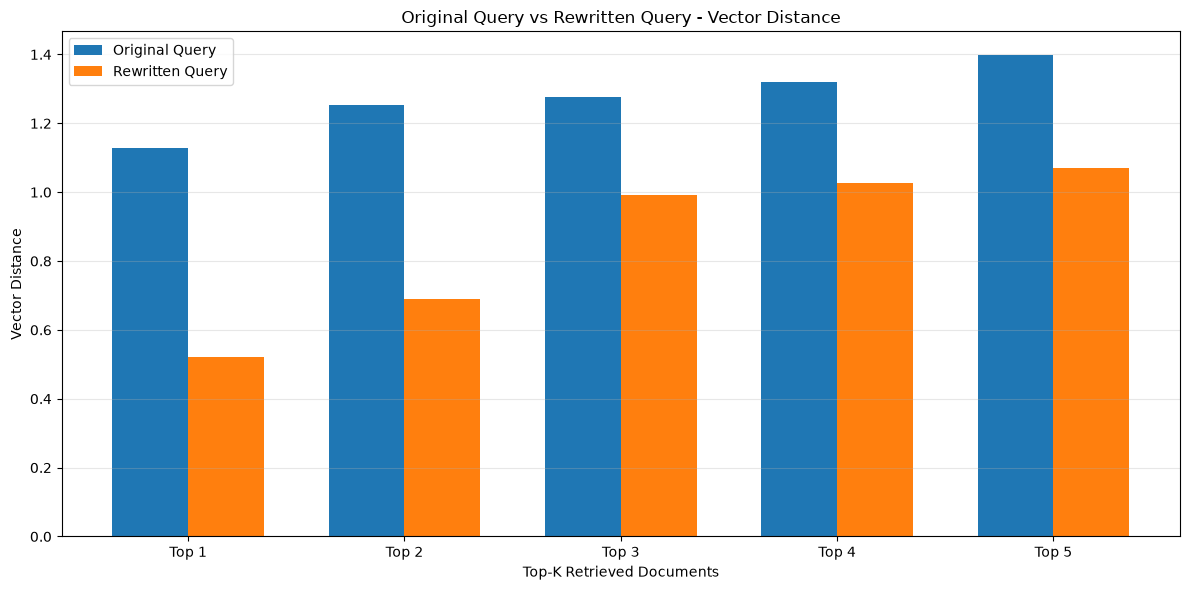

In [149]:
import matplotlib.pyplot as plt
import numpy as np

original_distances = [
    item["distance"] for item in original_results
]

rewritten_distances = [
    item["distance"] for item in retrieved_chunks
]

x = np.arange(1, 6)
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    original_distances,
    width,
    label="Original Query"
)

plt.bar(
    x + width/2,
    rewritten_distances,
    width,
    label="Rewritten Query"
)

plt.xlabel("Top-K Retrieved Documents")
plt.ylabel("Vector Distance")

plt.title("Original Query vs Rewritten Query - Vector Distance")

plt.xticks(x, [f"Top {i}" for i in x])
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Total document vectors: 36
Embedding started...
Embedding completed!
Embedding started...
Embedding completed!


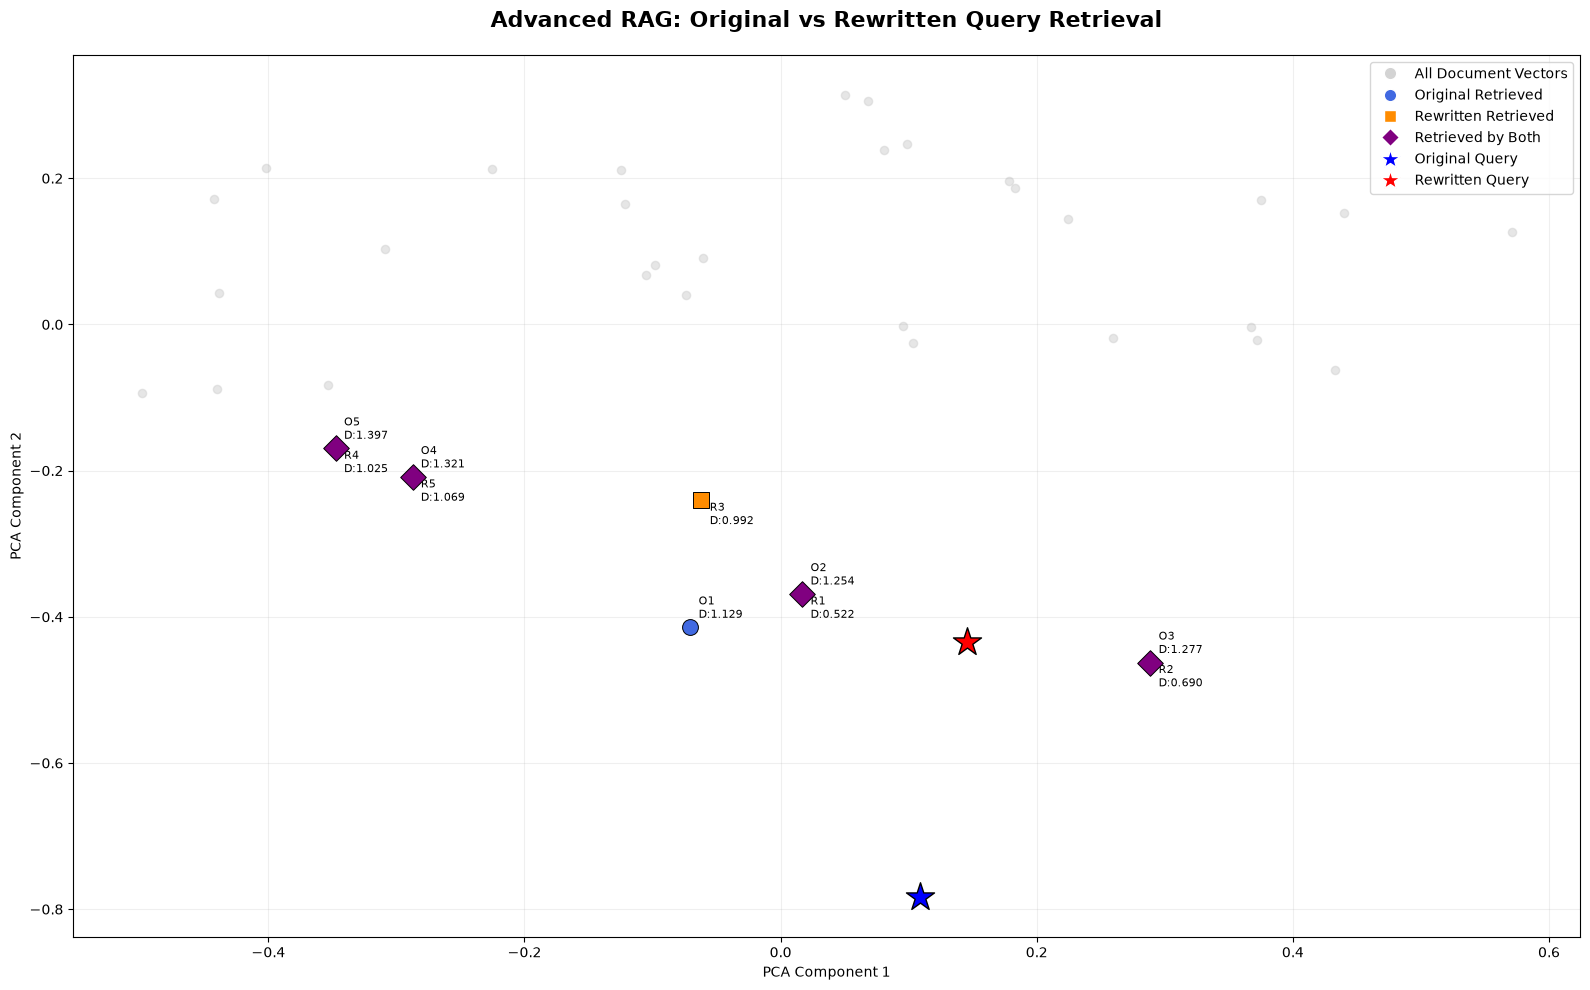

In [150]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from matplotlib.lines import Line2D

# ==========================================
# 1. Get ALL document vectors from ChromaDB
# ==========================================

all_data = collection.get(
    include=["embeddings"]
)

document_ids = all_data["ids"]
document_vectors = np.array(all_data["embeddings"])

print("Total document vectors:", len(document_vectors))


# ==========================================
# 2. Generate query embeddings
# ==========================================

original_query_vector = np.array(
    create_embeddings([user_query])[0]
)

rewritten_query_vector = np.array(
    create_embeddings([rewritten_query])[0]
)


# ==========================================
# 3. Prepare retrieved document IDs
# ==========================================

original_ids = {
    item["id"] for item in original_results
}

rewritten_ids = {
    item["id"] for item in retrieved_chunks
}

both_ids = original_ids & rewritten_ids


# ==========================================
# 4. Apply PCA dimensionality reduction
# ==========================================

all_vectors = np.vstack([
    document_vectors,
    original_query_vector,
    rewritten_query_vector
])

pca = PCA(n_components=2)

reduced_vectors = pca.fit_transform(all_vectors)

document_points = reduced_vectors[:len(document_vectors)]

original_query_point = reduced_vectors[-2]
rewritten_query_point = reduced_vectors[-1]


# ==========================================
# 5. Map document IDs to coordinates
# ==========================================

id_to_index = {
    doc_id: index
    for index, doc_id in enumerate(document_ids)
}


# ==========================================
# 6. Create professional visualization
# ==========================================

fig, ax = plt.subplots(figsize=(16, 10))

# All document vectors in background
ax.scatter(
    document_points[:, 0],
    document_points[:, 1],
    color="lightgray",
    alpha=0.55,
    s=35,
    label="All Document Vectors",
    zorder=1
)

# Original query retrieved chunks
for rank, item in enumerate(original_results, start=1):

    idx = id_to_index[item["id"]]
    point = document_points[idx]

    ax.scatter(
        point[0],
        point[1],
        color="royalblue",
        edgecolors="black",
        linewidths=0.7,
        s=130,
        zorder=3
    )

    ax.annotate(
        f"O{rank}\nD:{item['distance']:.3f}",
        (point[0], point[1]),
        xytext=(6, 7),
        textcoords="offset points",
        fontsize=8
    )


# Rewritten query retrieved chunks
for rank, item in enumerate(retrieved_chunks, start=1):

    idx = id_to_index[item["id"]]
    point = document_points[idx]

    if item["id"] not in both_ids:
        ax.scatter(
            point[0],
            point[1],
            color="darkorange",
            edgecolors="black",
            linewidths=0.7,
            s=130,
            marker="s",
            zorder=4
        )

    else:
        # Shared result: both queries retrieved this chunk
        ax.scatter(
            point[0],
            point[1],
            color="purple",
            edgecolors="black",
            linewidths=0.7,
            s=170,
            marker="D",
            zorder=5
        )

    ax.annotate(
        f"R{rank}\nD:{item['distance']:.3f}",
        (point[0], point[1]),
        xytext=(6, -17),
        textcoords="offset points",
        fontsize=8
    )


# Original query position
ax.scatter(
    original_query_point[0],
    original_query_point[1],
    color="blue",
    marker="*",
    s=450,
    edgecolors="black",
    label="Original Query",
    zorder=6
)

# Rewritten query position
ax.scatter(
    rewritten_query_point[0],
    rewritten_query_point[1],
    color="red",
    marker="*",
    s=450,
    edgecolors="black",
    label="Rewritten Query",
    zorder=6
)


# ==========================================
# 7. Legend and styling
# ==========================================

legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="lightgray",
        markersize=9,
        label="All Document Vectors"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="royalblue",
        markersize=9,
        label="Original Retrieved"
    ),
    Line2D(
        [0], [0],
        marker="s",
        color="w",
        markerfacecolor="darkorange",
        markersize=9,
        label="Rewritten Retrieved"
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="w",
        markerfacecolor="purple",
        markersize=9,
        label="Retrieved by Both"
    ),
    Line2D(
        [0], [0],
        marker="*",
        color="w",
        markerfacecolor="blue",
        markersize=15,
        label="Original Query"
    ),
    Line2D(
        [0], [0],
        marker="*",
        color="w",
        markerfacecolor="red",
        markersize=15,
        label="Rewritten Query"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    frameon=True
)

ax.set_title(
    "Advanced RAG: Original vs Rewritten Query Retrieval",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()